In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sentinelhub import SHConfig
import getpass
import utils
import cdsapi
import xarray as xr
import requests

In [ ]:
# config = SHConfig()
# config.sh_client_id = getpass.getpass("Enter your SentinelHub client id")
# config.sh_client_secret = getpass.getpass("Enter your SentinelHub client secret")
# config.sh_token_url = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
# config.sh_base_url = "https://sh.dataspace.copernicus.eu"
# config.save("cdse")


In [2]:
from sentinelhub import SHConfig
config = SHConfig("cdse")

In [3]:
# coordinates for Empordà with irrigated crops (rice), dry farmlands (cereals), forest and scrub
bbox_coords = [2.97, 41.92, 3.19, 42.10]
resolution = 20
dates = [['2023', '07']]
# dates = ("2023-07-01", "2023-07-31")

ds = utils.get_ndmi(bbox_coords, resolution, dates, config)


In [4]:
def get_mat(ds, date, variable):
    n_lat = ds.sizes['lat']
    n_lon = ds.sizes['lon']
    mat = ds.sel(time = date)[variable].to_numpy()
    mat = mat.reshape((n_lat, n_lon))
    return mat

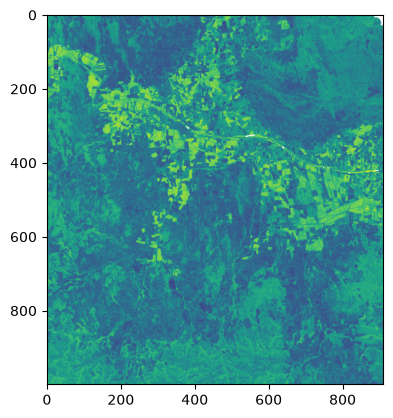

In [5]:
ndmi_mat = get_mat(ds, '2023-07-01', 'ndmi_median')
plt.imshow(ndmi_mat)

In [6]:
# study area, period and variables
coords = [2.97, 41.92, 3.19, 42.10]   # Baix Empordà
ndmi_resolution = 20
months = [[d.year, d.month] for d in pd.date_range("2017-04", "2025-12", freq="MS")]

era5_variables = [
    "total_precipitation",
    "2m_temperature",
    "potential_evaporation",
    "total_evaporation",
    "volumetric_soil_water_layer_1",
    "volumetric_soil_water_layer_2",
]

In [7]:
# 1. get raw data, each at its native resolution
ndmi = utils.get_ndmi(coords, ndmi_resolution, months, config)   # 20 m, defines the grid
era5 = utils.get_era5(coords, months, era5_variables)            # ~9 km
dem = utils.get_dem(coords)                                      # 30 m
wc = utils.get_worldcover(coords)                                # 10 m

In [8]:
# 2. bring each source onto the NDMI grid, with its features, and merge
cube = xr.merge([
    ndmi,
    utils.era5_to_grid(era5, ndmi),
    utils.dem_to_grid(dem, ndmi),
    utils.worldcover_to_grid(wc, ndmi),
])
cube

<xarray.Dataset> Size: 3GB
Dimensions:                (time: 105, lat: 1000, lon: 910)
Coordinates:
  * time                   (time) datetime64[us] 840B 2017-04-01 ... 2025-12-01
  * lat                    (lat) float64 8kB 42.1 42.1 42.1 ... 41.92 41.92
  * lon                    (lon) float64 7kB 2.97 2.97 2.971 ... 3.189 3.19 3.19
Data variables: (12/25)
    ndmi_median            (time, lat, lon) float32 382MB 0.1721 ... -0.03355
    clear_count            (time, lat, lon) float32 382MB 6.0 6.0 ... 3.0 3.0
    tp                     (time, lat, lon) float32 382MB 0.001044 ... 0.007493
    t2m                    (time, lat, lon) float32 382MB 287.3 287.3 ... 284.8
    pev                    (time, lat, lon) float32 382MB -0.006147 ... -0.00...
    e                      (time, lat, lon) float32 382MB -0.002727 ... -0.00...
    ...                     ...
    lc_bare_sparse         (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0
    lc_snow_ice            (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0
    lc_water               (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0
    lc_herbaceous_wetland  (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0
    lc_mangroves           (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0
    lc_moss_lichen         (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0

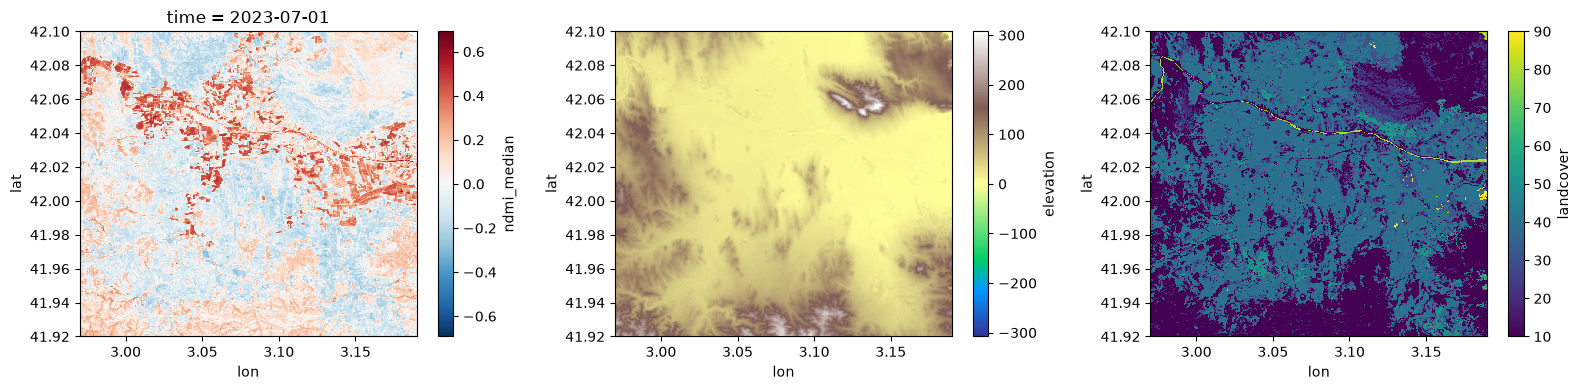

In [9]:
# quick check of the cube
fig, axes = plt.subplots(1, 3, figsize = (16, 4))
cube.ndmi_median.sel(time = "2023-07-01").plot(ax = axes[0])
cube.elevation.plot(ax = axes[1], cmap = "terrain")
cube.landcover.plot(ax = axes[2])
plt.tight_layout()